In [27]:
# Generic
import numpy as np
from numpy import *
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Torch
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset,DataLoader
from torchvision import models, transforms
from torchvision.models import vgg16, VGG16_Weights
import torch.optim as optim
from torch.utils.data import Subset

# Custom dataset
from dataset import ImageDataset

# Set the seed of Torch
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Check for GPU availability

In [28]:
import torch
import sys
import os

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
print("Hostname:", os.uname().nodename)

Python executable: /opt/scopia/bin/python3.11
PyTorch version: 2.5.1+cu121
CUDA version: 12.1
CUDA available: True
GPU count: 2
Hostname: fc76a60b252b


# Dataset loading

In [29]:
info = pd.DataFrame(
    np.load("/home/jovyan/work/HWD+/Datasets/WriterInfo.npy", allow_pickle=True)
)

labels = info.drop(columns=[1,2, 3, 4, 5, 6, 7, 8])
labels = labels.rename(columns={
    0: "label",
})

images=np.load(r"/home/jovyan/work/HWD+/Datasets/Images(500x500).npy")

labels["image"] = list(images)

labels_array = labels["label"].to_numpy()
dataset = ImageDataset(images, labels_array)

# Splitting and data loader

## Splitting

In [30]:
# Get labels
labels = dataset.labels

# First split: 80% training, 20% temporary
train_idx, temp_idx = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

# Get labels for temporary set
temp_labels = [labels[i] for i in temp_idx]

# Second split: 10% validation, 10% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=temp_labels,
    random_state=42
)

# Create PyTorch subsets
train = Subset(dataset, train_idx)
val = Subset(dataset, val_idx)
test = Subset(dataset, test_idx)

In [31]:
print(f'Training set length: {len(train)}')
print(f'Validation set length: {len(val)}')
print(f'Test set length: {len(test)}')

print(type(train))

Training set length: 10864
Validation set length: 1358
Test set length: 1358
<class 'torch.utils.data.dataset.Subset'>


## Data Loader

In [32]:
# Define batch size to avoid RAM problems
batch_size = 10

# Shuffle to avoid integrating some "order induced" bias
train_loader = DataLoader(
    dataset=train,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    dataset=val,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    dataset=test,
    batch_size=batch_size,
    shuffle=False
)

# VGG16 witth DFN's NN

## Hyper Parameters

In [33]:
# Hyper Parameters
learning_rate=0.1
Epochs=10 # Number of iterations

## VGG16

In [34]:
from models.vgg16_dfn import Vgg16_dfn
from functions.loss_functions_dfn_v1 import total_loss
from functions.sparsemax import sparsemax

In [35]:
# Number of classes
num_classes = 10

# Choose device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
# Instantiate model
vgg_dfn = Vgg16_dfn(
    pretrained=True
).to(device)

# Move model to device
vgg_dfn = vgg_dfn.to(device)

## Training

In [36]:
import time
# Optimizer updates the trainable parameters in BOTH NN1 and NN2
optimizer = optim.Adam(vgg_dfn.parameters(), lr=1e-4)

num_epochs = 5

total_start_time = time.time()

for epoch in range(num_epochs):
    
    epoch_start_time = time.time()
    vgg_dfn.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    # Training
    for images, true_labels in train_loader:
        images = images.to(device)
        true_labels = true_labels.to(device)
        # One hot encoding like a dfn
        true_dfns = F.one_hot(
            true_labels.long(),
            num_classes=10
        ).float()
        # 1. Clear gradients from the previous iteration
        optimizer.zero_grad()

        # 2. Forward propagation
        pi, split_vectors, dfn_vectors, class_logits = vgg_dfn(images)

        # 3. Calculate the combined loss
        loss, loss_pi, loss_dfn = total_loss(
            pi,
            dfn_vectors,
            true_dfns,       # Target DFNs for this batch
            lambda_pi=1.0,
            lambda_dfn=0.5
        )

        # 4. Backpropagation: calculate gradients
        loss.backward()

        # 5. Update NN1 and NN2 parameters
        optimizer.step()

        # 6. Compute Training Loss and accuracy
        train_loss += loss.item() * images.size(0)
        predictions = class_logits.argmax(dim=1)
        train_correct += (predictions == true_labels).sum().item()
        train_total += true_labels.size(0)
    
    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation
    vgg_dfn.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:           
            images = images.to(device)
            labels = labels.to(device).long()
            true_dfns = F.one_hot(
            labels.long(),
            num_classes=10).float()
            
            pi, split_vectors, dfn_vectors, class_logits = vgg_dfn(images)
            # 3. Calculate the combined loss
            loss, loss_pi, loss_dfn = total_loss(
                pi,
                dfn_vectors,
                true_dfns,       # Target DFNs for this batch
                lambda_pi=1.0,
                lambda_dfn=0.5
            )

            val_loss += loss.item() * images.size(0)

            predictions = class_logits.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # End epoch timer
    epoch_time = time.time() - epoch_start_time

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Time: {epoch_time:.2f} seconds"
    )

# End total timer
total_time = time.time() - total_start_time

print(f"\nTotal training time: {total_time:.2f} seconds")
print(f"Total training time: {total_time / 60:.2f} minutes")

Epoch [1/5] Train Loss: 4.1240 | Train Accuracy: 0.8748 | Val Loss: 1.0296 | Val Accuracy: 0.9735 | Time: 232.38 seconds
Epoch [2/5] Train Loss: 1.0680 | Train Accuracy: 0.9731 | Val Loss: 0.9837 | Val Accuracy: 0.9720 | Time: 231.78 seconds
Epoch [3/5] Train Loss: 0.7644 | Train Accuracy: 0.9809 | Val Loss: 0.6779 | Val Accuracy: 0.9860 | Time: 231.58 seconds
Epoch [4/5] Train Loss: 0.5582 | Train Accuracy: 0.9877 | Val Loss: 0.8271 | Val Accuracy: 0.9823 | Time: 230.99 seconds
Epoch [5/5] Train Loss: 0.6164 | Train Accuracy: 0.9862 | Val Loss: 0.7467 | Val Accuracy: 0.9845 | Time: 230.86 seconds

Total training time: 1157.58 seconds
Total training time: 19.29 minutes


In [37]:
torch.save(
    vgg_dfn.state_dict(),
    "/home/jovyan/work/HWD+/saved_models/vgg_dfn_trained.pth"
)

In [40]:
def calculate_accuracy(model, dataloader, device):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device).long()

            # Forward pass
            pi, split_vectors, dfn_vectors, class_logits = model(images)

            # Predicted class
            predictions = torch.argmax(pi, dim=1)

            # Count correct predictions
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total

    return accuracy

In [42]:
train_accuracy = calculate_accuracy(
    vgg_dfn, train_loader, device
)

val_accuracy = calculate_accuracy(
    vgg_dfn, val_loader, device
)

test_accuracy = calculate_accuracy(
    vgg_dfn, test_loader, device
)

print(f"Train accuracy: {train_accuracy * 100:.2f}%")
print(f"Val accuracy:   {val_accuracy * 100:.2f}%")
print(f"Test accuracy:  {test_accuracy * 100:.2f}%")

Train accuracy: 99.64%
Val accuracy:   98.45%
Test accuracy:  98.45%


In [44]:
import torch
from torchvision import transforms
from PIL import Image
from pathlib import Path

# Folder containing images
image_folder = Path("my_images")

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((500, 500)),
    transforms.ToTensor()
])

# Load images
images = []

for file in image_folder.iterdir():
    if file.suffix.lower() in [".png", ".jpg", ".jpeg"]:
        img = Image.open(file).convert("RGB")
        img = transform(img)
        images.append(img)

# Create batch tensor
images = torch.stack(images)

print("Images shape:", images.shape)

# Move images to device
images = images.to(device)

# Set model to evaluation mode
vgg_dfn.eval()

# Forward pass
with torch.no_grad():
    pi, split_vectors, dfn_vectors, class_logits = vgg_dfn(images)

    # Predicted class
    predictions = torch.argmax(pi, dim=1)

print("Predictions:", predictions)

Images shape: torch.Size([10, 3, 500, 500])
Predictions: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], device='cuda:0')


In [45]:
# Save the NN
torch.save(vgg_dfn.state_dict(), "/home/jovyan/work/HWD+/saved_models/vgg_dfn_trained.pth")

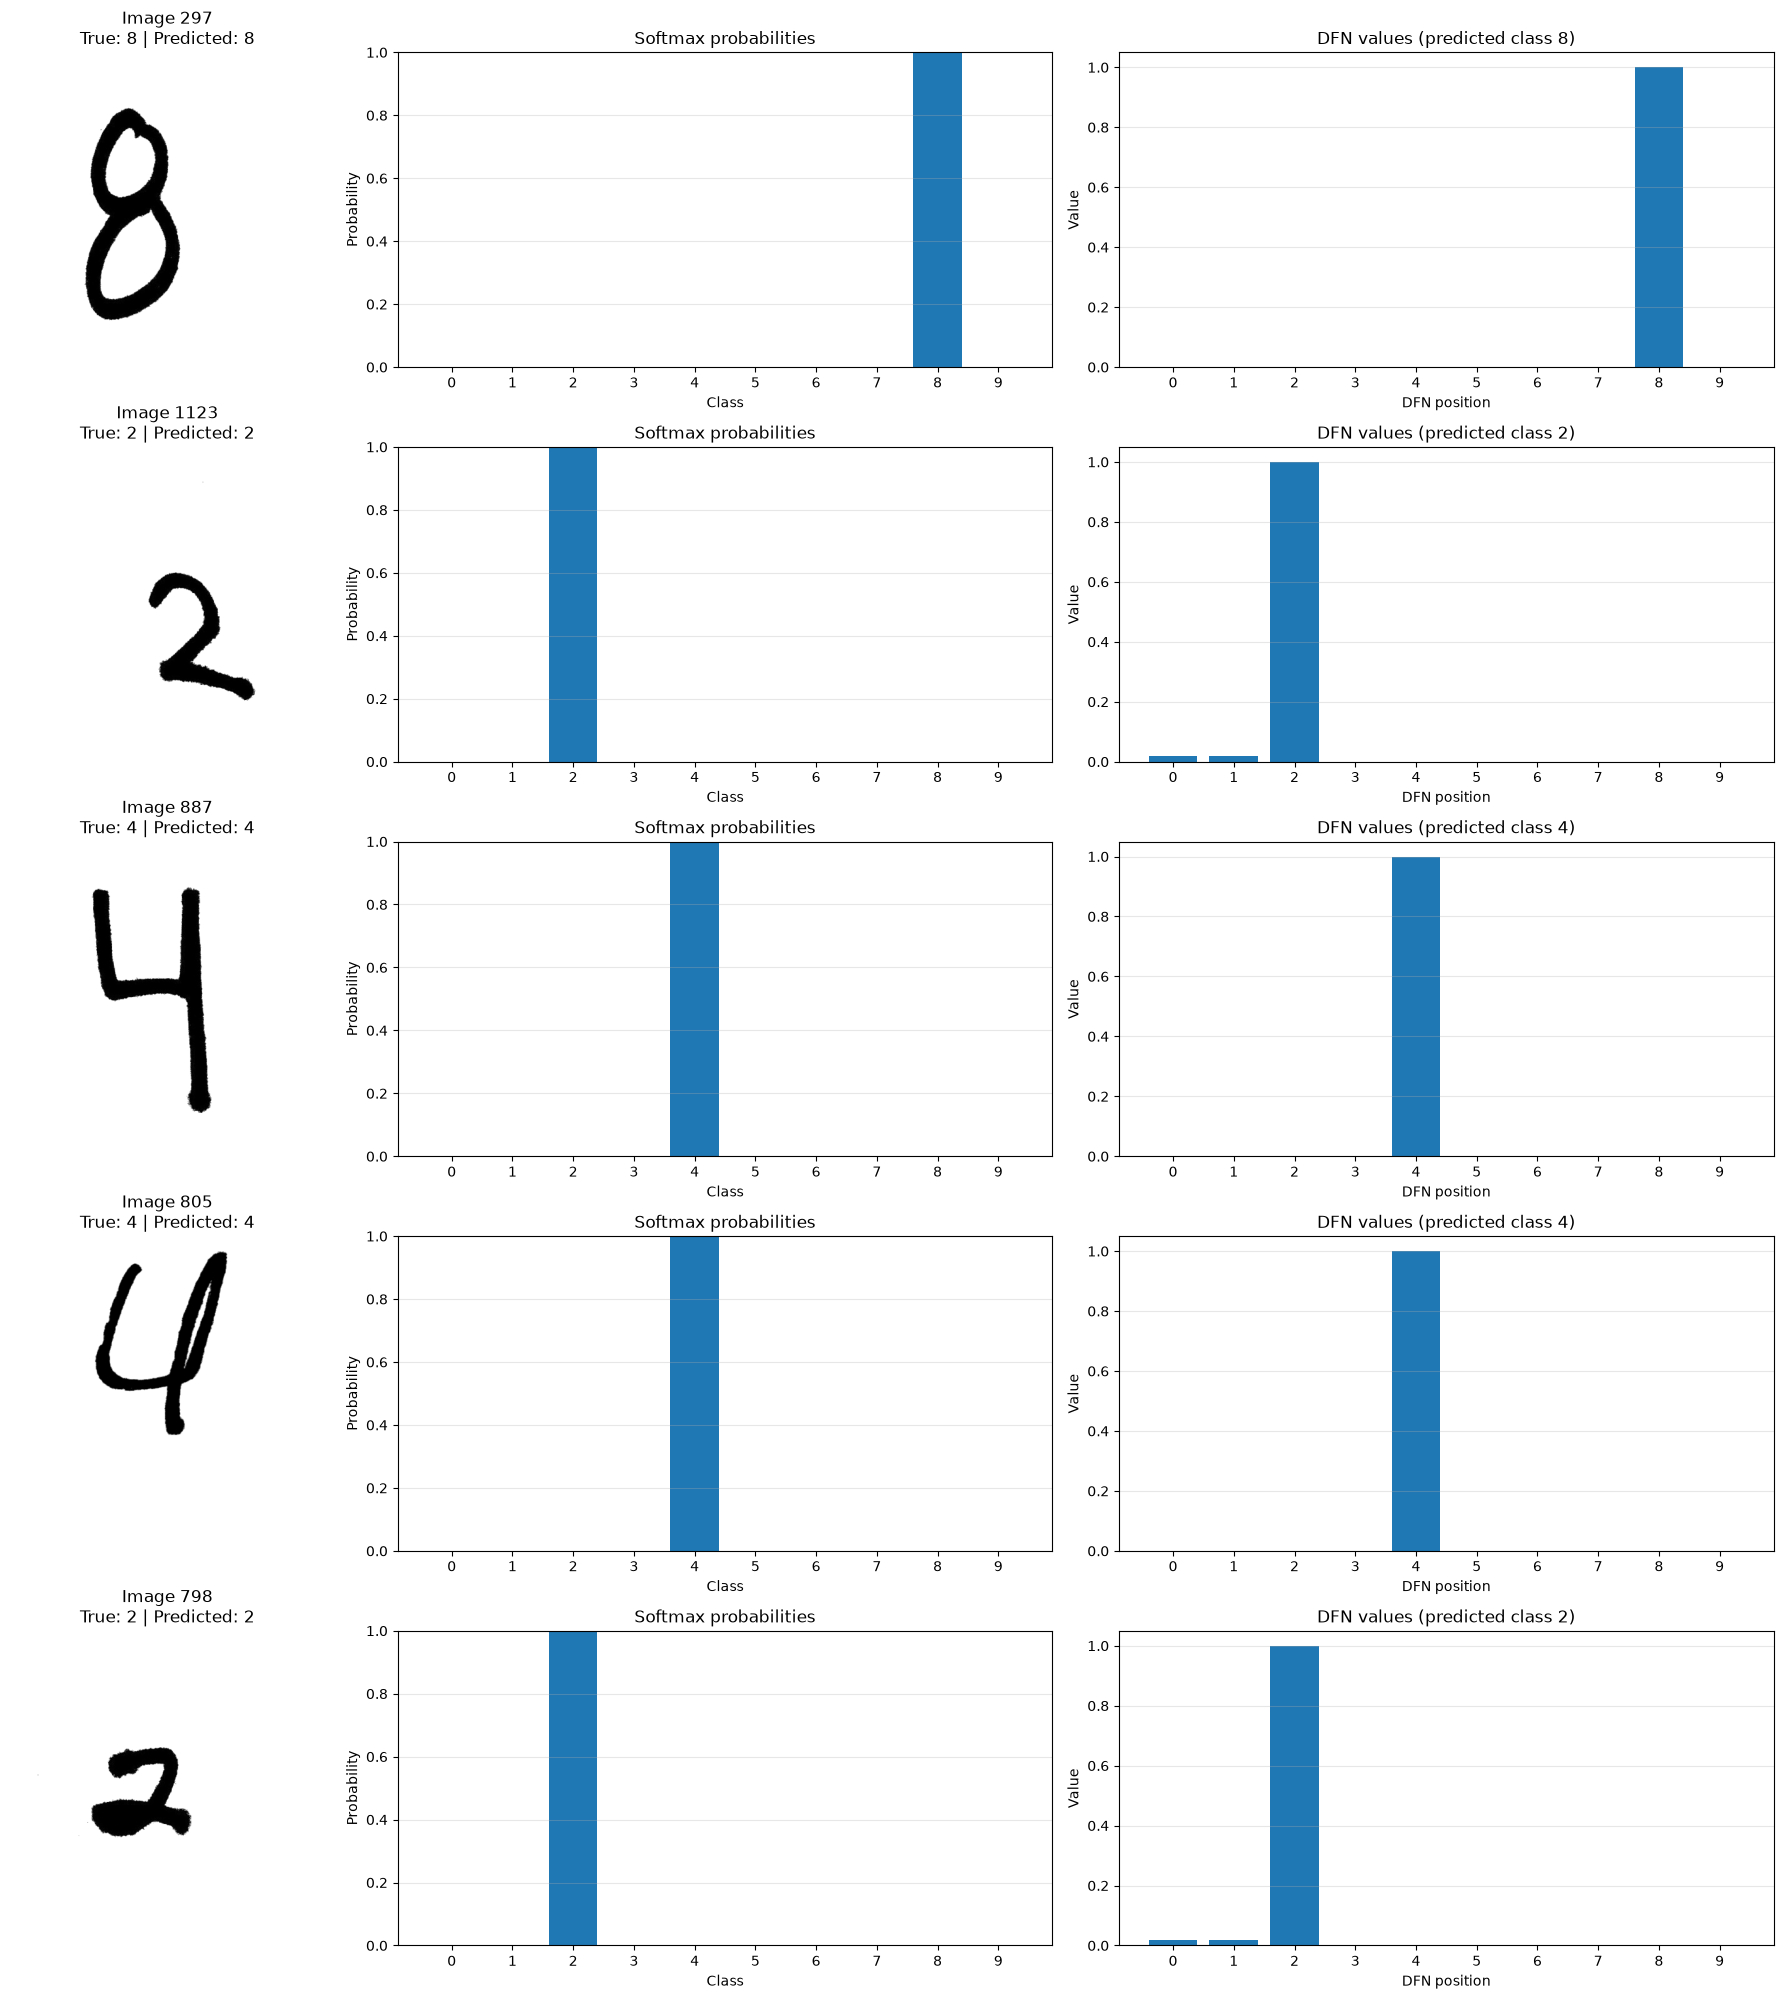

In [50]:
import random as py_random
# How many test images to display
num_images = 5

indices = py_random.sample(range(len(test)), num_images)

fig, axes = plt.subplots(
    num_images, 3,
    figsize=(18, 4 * num_images),
    gridspec_kw={"width_ratios": [1, 2, 2]}
)

for i, idx in enumerate(indices):

    image, label = test[idx]

    input_image = image.unsqueeze(0).to(device)

    vgg_dfn.eval()

    with torch.no_grad():
        pi, split_vectors, dfn_vectors, class_logits = vgg_dfn(input_image)

        probabilities = torch.softmax(class_logits, dim=1)[0]
        prediction = class_logits.argmax(dim=1).item()

        prediction_dfn = dfn_vectors[prediction][0]

    # Convert to NumPy
    values = probabilities.cpu().numpy()
    values_dfn = prediction_dfn.cpu().numpy()

    # Convert image to HWC
    img = image.detach().cpu().permute(1, 2, 0).numpy()
    img = img / 255.0

    # =================================
    # 1. DISPLAY IMAGE
    # =================================

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(
        f"Image {idx}\nTrue: {label.item()} | Predicted: {prediction}"
    )
    axes[i, 0].axis("off")

    # =================================
    # 2. SOFTMAX PROBABILITIES
    # =================================

    positions = range(len(values))

    axes[i, 1].bar(positions, values)
    axes[i, 1].set_title("Softmax probabilities")
    axes[i, 1].set_xlabel("Class")
    axes[i, 1].set_ylabel("Probability")
    axes[i, 1].set_xticks(list(positions))
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].grid(axis="y", alpha=0.3)

    # =================================
    # 3. DFN VALUES
    # =================================

    dfn_positions = range(len(values_dfn))

    axes[i, 2].bar(dfn_positions, values_dfn)
    axes[i, 2].set_title(f"DFN values (predicted class {prediction})")
    axes[i, 2].set_xlabel("DFN position")
    axes[i, 2].set_ylabel("Value")
    axes[i, 2].set_xticks(list(dfn_positions))
    axes[i, 2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

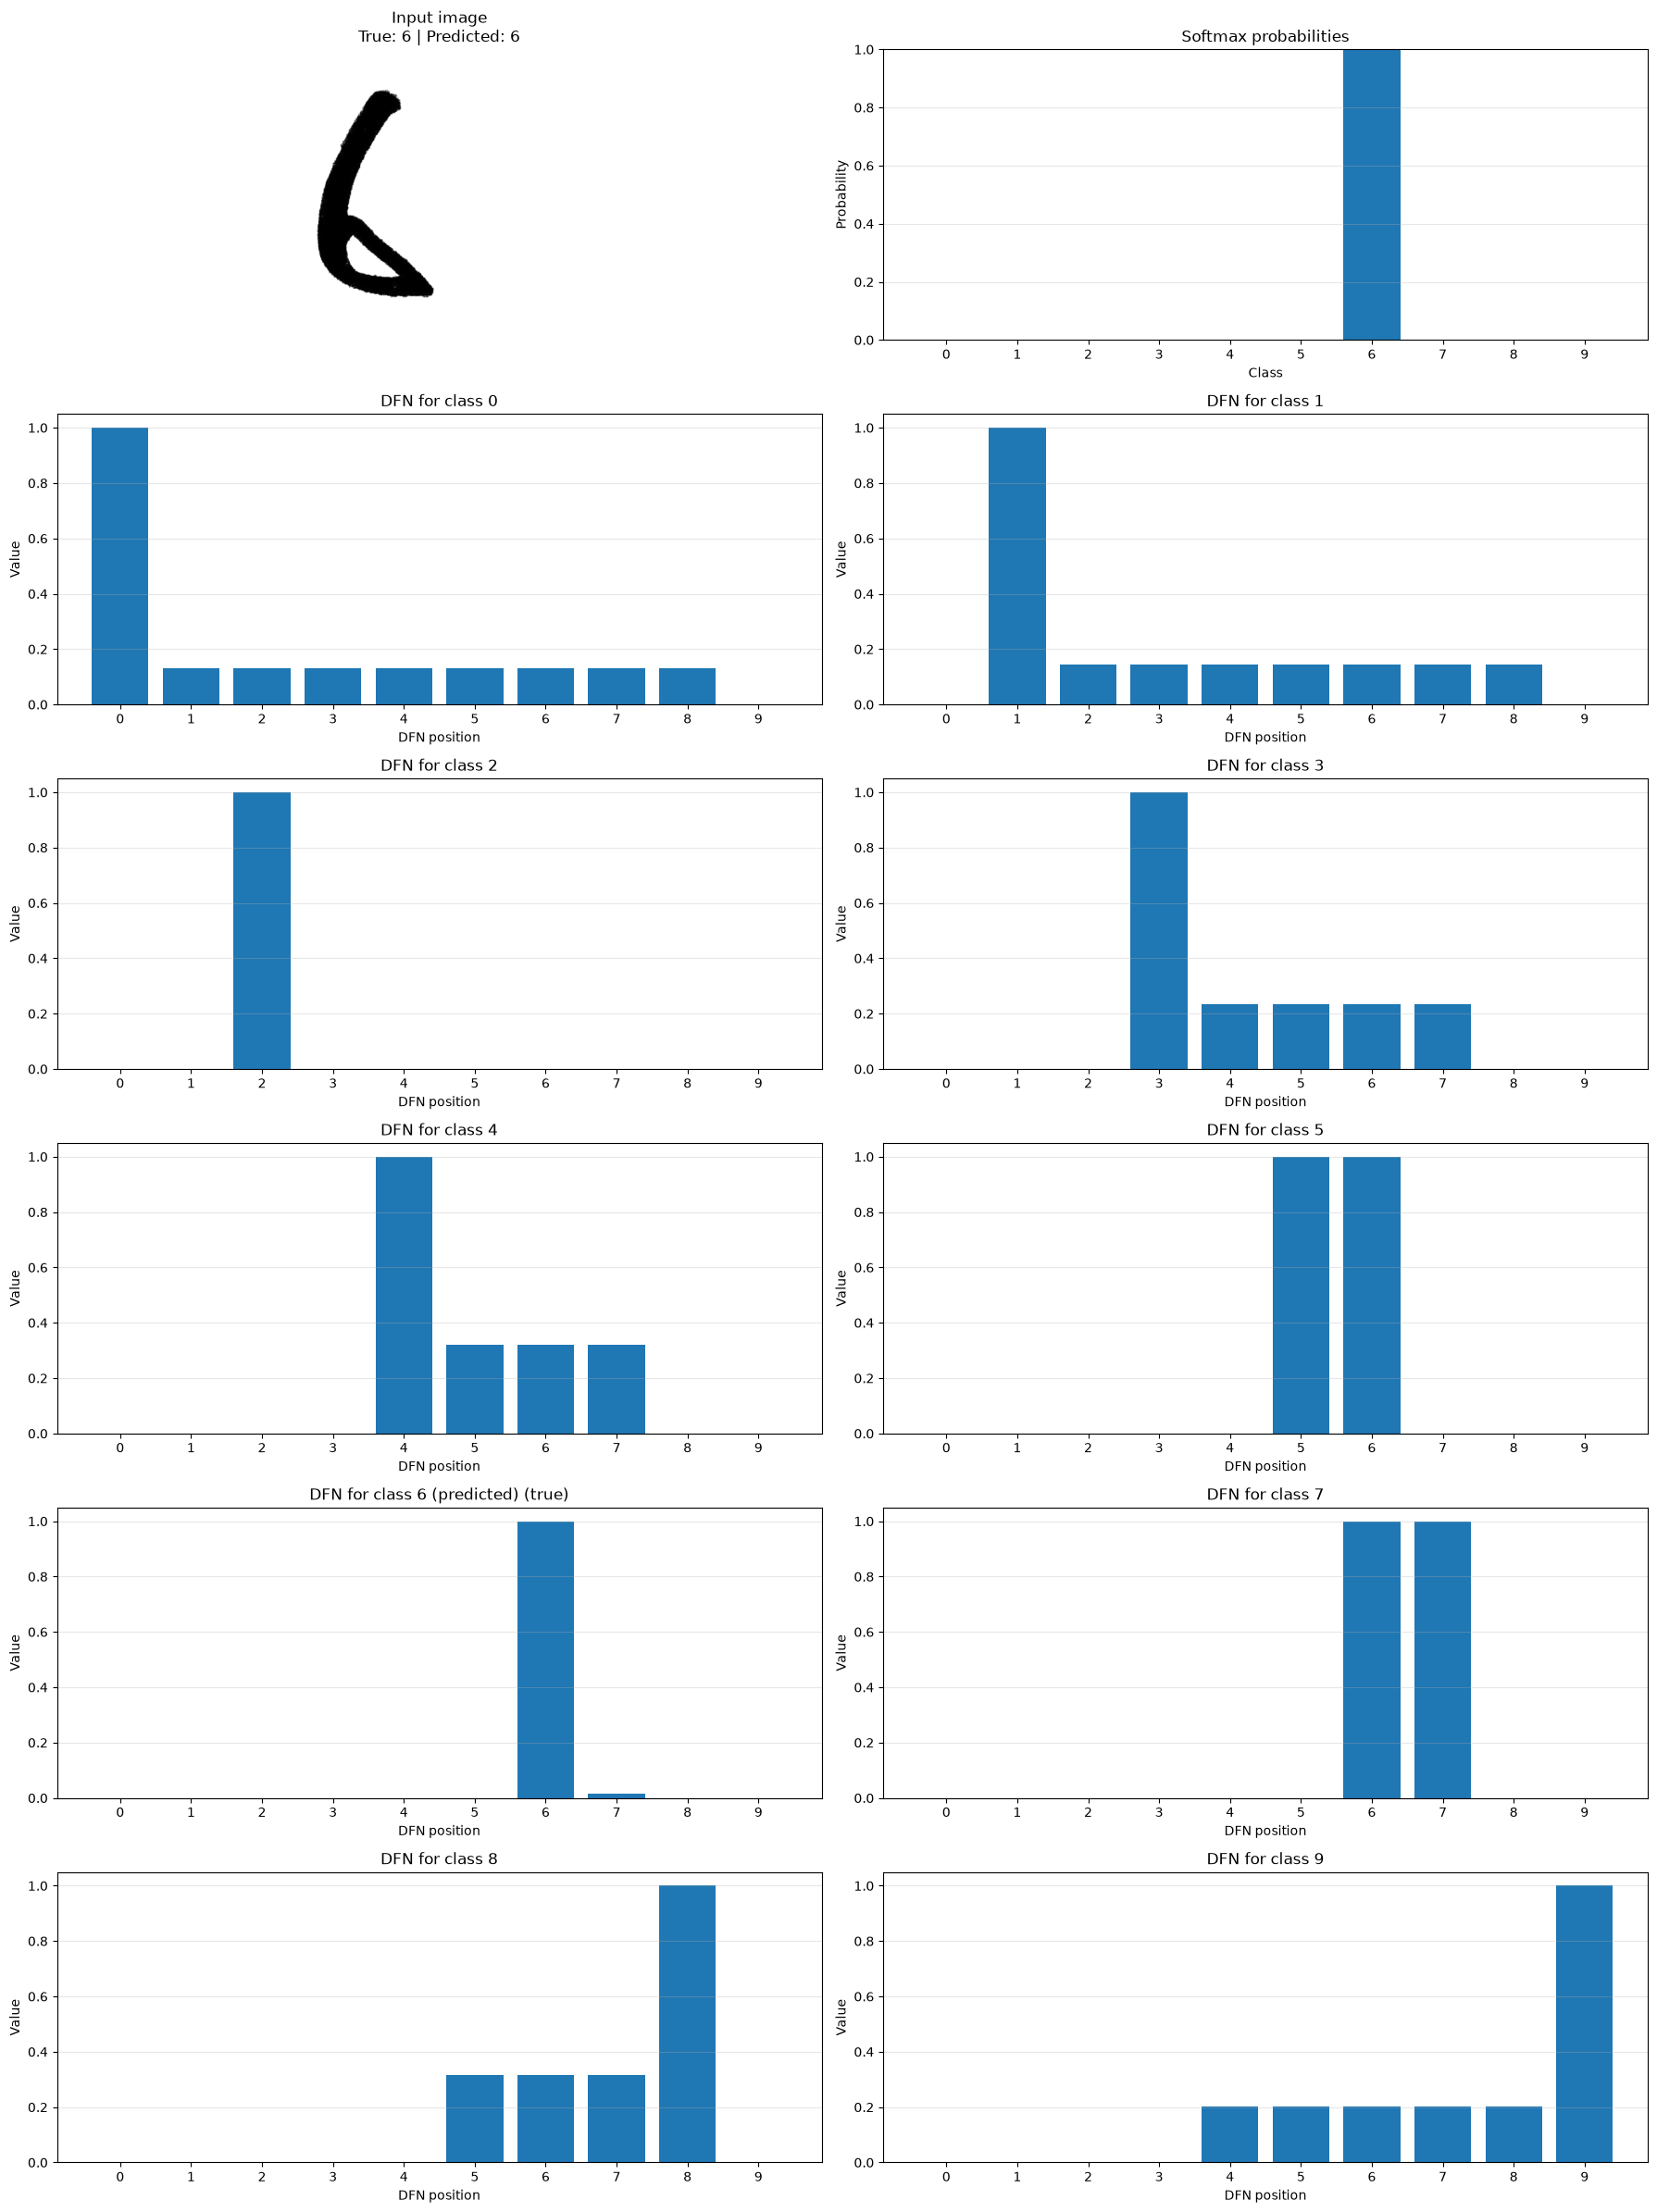

In [52]:
# Select ONE random test image
idx = py_random.randrange(len(test))

image, label = test[idx]

input_image = image.unsqueeze(0).to(device)

vgg_dfn.eval()

with torch.no_grad():
    pi, split_vectors, dfn_vectors, class_logits = vgg_dfn(input_image)

    probabilities = torch.softmax(class_logits, dim=1)[0]
    prediction = class_logits.argmax(dim=1).item()

# Convert to NumPy
values = probabilities.cpu().numpy()

# Convert image to HWC
img = image.detach().cpu().permute(1, 2, 0).numpy()
img = img / 255.0

# =================================
# CREATE FIGURE
# =================================

fig = plt.figure(figsize=(18, 24))

# =================================
# 1. INPUT IMAGE
# =================================

ax1 = plt.subplot(6, 2, 1)

ax1.imshow(img)
ax1.set_title(
    f"Input image\nTrue: {label.item()} | Predicted: {prediction}"
)
ax1.axis("off")

# =================================
# 2. SOFTMAX PROBABILITIES
# =================================

ax2 = plt.subplot(6, 2, 2)

ax2.bar(range(10), values)
ax2.set_title("Softmax probabilities")
ax2.set_xlabel("Class")
ax2.set_ylabel("Probability")
ax2.set_xticks(range(10))
ax2.set_ylim(0, 1)
ax2.grid(axis="y", alpha=0.3)

# =================================
# 3. ALL TEN DFN VECTORS
# =================================

for class_idx in range(10):

    ax = plt.subplot(6, 2, class_idx + 3)

    # Extract the DFN for this class
    values_dfn = dfn_vectors[class_idx][0].detach().cpu().numpy()

    ax.bar(range(len(values_dfn)), values_dfn)

    ax.set_title(
        f"DFN for class {class_idx}"
        + (" (predicted)" if class_idx == prediction else "")
        + (" (true)" if class_idx == label.item() else "")
    )

    ax.set_xlabel("DFN position")
    ax.set_ylabel("Value")
    ax.set_xticks(range(len(values_dfn)))
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()